# 03 — Détection d'anomalies : SVM

Cible : `label` (0 = normal, 1 = attaque) · Entrée : `data/processed/*` (notebook 01) · Classe minoritaire = **normal** (~23 %).

## Workflow
1. Chargement ; pourquoi le SVM exige **log1p + standardisation**
2. **Baseline** : SVM linéaire par défaut
3. **Équilibrage** (CV, règle de parcimonie, SMOTENC inclus) et réglage de `C` du SVM linéaire (`LinearSVC`, courbe de validation)
4. **SVM à noyau RBF** (`SVC`) : grille `C × gamma` sur 10 000 lignes, apprentissage final sur un sous-échantillon stratifié de 25 000 lignes (coût ≈ O(n²))
5. Variante **Nyström + LinearSVC** sur tout le train
6. Comparaison des variantes en validation (F1 macro), choix du SVM retenu, courbe d'apprentissage et écart train / validation
7. **Seuil** (marge de décision) et **calibration** des probabilités, sur la validation uniquement
8. **Test lu une seule fois**
9. Interprétation (coefficients, permutation), analyse des erreurs, sauvegarde

> Un SVM ne produit pas de probabilités mais une **marge** signée (`decision_function`, seuil naturel 0). Platt / isotonique la transforment en probabilité.
> Les scores sont plus bas qu'avant le correctif de fuite (doublons train/test retirés, `src_port` retiré) : c'est attendu.

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import ml_utils as U
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_validate, train_test_split
from sklearn.metrics import confusion_matrix, make_scorer, recall_score, brier_score_loss
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
U.set_style(); U.set_seeds()
RS = U.RANDOM_STATE
N_JOBS = 5
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]; TYPE_ORDER = U.get_type_order(cfg)
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["label"].to_numpy(), y_va["label"].to_numpy(), y_te["label"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
print("Part d'attaques (train/valid/test) :", ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4))

{'train': (65007, 35), 'valid': (21482, 35), 'test': (21438, 35)}
Part d'attaques (train/valid/test) : 0.7674 0.7714 0.773


## 1. Pipeline SVM

Le SVM est **sensible à l'échelle** : les octets (jusqu'à 10⁹) écraseraient les drapeaux 0/1. Le préprocesseur applique `imputation → log1p → StandardScaler` aux numériques (`scale=True`)
et un one-hot aux catégorielles, ajustés sur le train uniquement (et refaits dans chaque pli de CV). `U.make_model_pipeline` ajoute le rééchantillonnage éventuel (jamais sur les plis de validation).
Poids de classe : `class_weight="balanced"` sur l'estimateur. Variantes : `linear` (LinearSVC), `rbf` (SVC exact), `nystroem` (approximation RBF à 300 composantes + LinearSVC).

In [2]:
def make_svm(kind="linear", strategy="none", **p):
    cw = "balanced" if strategy == "class_weight" else None
    if kind == "linear":
        est = LinearSVC(dual="auto", max_iter=20000, class_weight=cw, random_state=RS, **p)
    elif kind == "rbf":
        est = SVC(kernel="rbf", cache_size=800, class_weight=cw, random_state=RS, **p)
    elif kind == "nystroem":
        est = Pipeline([("nys", Nystroem(kernel="rbf", gamma=p["gamma"], n_components=p.get("n_components", 300), random_state=RS)),
                        ("svm", LinearSVC(dual="auto", max_iter=20000, C=p["C"], class_weight=cw, random_state=RS))])
    else:
        raise ValueError(kind)
    return U.make_model_pipeline(est, NUM, CAT, strategy=strategy, scale=True, random_state=RS)

score_fn = lambda m, X: m.decision_function(X)        # marge signée : > 0 => attaque
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(50000, random_state=RS).index; Xs, ys = X_train.loc[sub], y_tr.loc[sub, "label"].to_numpy()
tr_eval = X_train.sample(20000, random_state=RS + 1).index      # échantillon de train pour mesurer l'écart train / validation (SVC exact trop lent sur tout le train)
make_svm()

,steps,"[('pre', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_lin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_

## 2. Baseline
SVM linéaire, `C = 1`, sans équilibrage, sur **tout le train** ; évalué en validation (marge > 0).

In [3]:
t0 = time.time(); base = make_svm("linear", "none").fit(X_train, ytr); t_base = time.time() - t0
s_base = score_fn(base, X_valid); base_valid = U.binary_metrics(yva, (s_base > 0).astype(int), scores=s_base)
print(f"Temps : {t_base:.1f}s"); display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps : 3.8s


,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,mcc,tn,fp,fn,tp,fpr,fnr,roc_auc,pr_auc
baseline (validation),0.9929,0.9881,0.9939,0.9970,0.9792,0.9954,0.9899,0.9929,0.9799,4808.0000,102.0000,50.0000,16522.0000,0.0208,0.0030,0.9983,0.9994


## 3. SVM linéaire : équilibrage et réglage de `C`
Même protocole que le Random Forest (CV stratifiée à 3 plis sur 50 000 lignes, rééchantillonnage refait dans chaque pli). Choix par **règle de parcimonie** :
la stratégie la plus simple (aucun < poids de classe < ROS < SMOTE < SMOTENC) dont le F1 macro est à moins d'un écart-type du meilleur.

none              15s  F1 macro = 0.9903 ± 0.0011


class_weight       3s  F1 macro = 0.9899 ± 0.0013


ros                6s  F1 macro = 0.9900 ± 0.0013


smote              4s  F1 macro = 0.9899 ± 0.0012


smotenc           19s  F1 macro = 0.9898 ± 0.0012


,f1_macro,pr_auc,balanced_accuracy,recall,specificity
Aucun,0.9903 ± 0.0011,0.9993 ± 0.0000,0.9898 ± 0.0012,0.9960 ± 0.0005,0.9837 ± 0.0019
Poids de classe,0.9899 ± 0.0013,0.9994 ± 0.0000,0.9921 ± 0.0010,0.9934 ± 0.0009,0.9907 ± 0.0012
Sur-échantillonnage aléatoire,0.9900 ± 0.0013,0.9994 ± 0.0000,0.9922 ± 0.0010,0.9934 ± 0.0009,0.9910 ± 0.0011
SMOTE,0.9899 ± 0.0012,0.9994 ± 0.0001,0.9920 ± 0.0011,0.9934 ± 0.0007,0.9905 ± 0.0016
SMOTENC,0.9898 ± 0.0012,0.9994 ± 0.0000,0.9920 ± 0.0013,0.9933 ± 0.0006,0.9906 ± 0.0020



=> Meilleur F1 macro brut : none ; stratégie retenue (parcimonie) : none


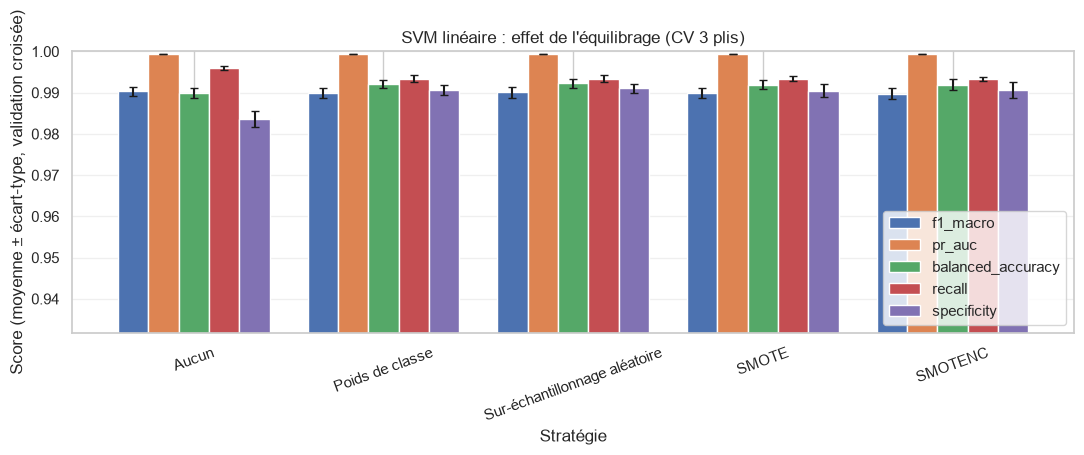

In [4]:
SCORING = {"f1_macro": "f1_macro", "pr_auc": "average_precision", "balanced_accuracy": "balanced_accuracy",
           "recall": "recall", "specificity": make_scorer(recall_score, pos_label=0)}
METRICS = list(SCORING)
rows = {}
for name in U.STRATEGIES:
    t0 = time.time()
    r = cross_validate(make_svm("linear", name), Xs, ys, cv=cv, n_jobs=3, scoring=SCORING)
    row = {}
    for m in METRICS:
        row[m] = r[f"test_{m}"].mean(); row[f"{m}_std"] = r[f"test_{m}"].std()
    row["temps_s"] = time.time() - t0
    rows[name] = row
    print(f"{name:13s} {time.time()-t0:6.0f}s  F1 macro = {row['f1_macro']:.4f} ± {row['f1_macro_std']:.4f}")
bal = pd.DataFrame(rows).T
disp = pd.DataFrame({m: bal[m].map("{:.4f}".format) + " ± " + bal[f"{m}_std"].map("{:.4f}".format) for m in METRICS})
display(disp.rename(index=U.STRATEGY_LABELS))
best_strategy = U.select_by_parsimony(bal, "f1_macro", "f1_macro_std", list(U.STRATEGIES))
argmax_strategy = bal["f1_macro"].idxmax()
print(f"\n=> Meilleur F1 macro brut : {argmax_strategy} ; stratégie retenue (parcimonie) : {best_strategy}")
fig, ax = plt.subplots(figsize=(11, 4.5))
U.plot_cv_comparison(bal.rename(index=U.STRATEGY_LABELS), METRICS, [f"{m}_std" for m in METRICS], "SVM linéaire : effet de l'équilibrage (CV 3 plis)", ax=ax)
plt.tight_layout(); U.savefig(fig, "03_balancing_cv"); plt.show()

### Réglage de `C` et courbe de validation
`C` contrôle le compromis marge / erreurs (grand `C` = peu de tolérance, risque de surapprentissage). On compare score d'entraînement et de validation croisée pour juger du biais / variance. Quand le score atteint un plateau, on retient le **plus petit `C`** à moins d'un écart-type du meilleur (le plus régularisé) plutôt qu'un `argmax` arbitraire sur le plateau.

,C,mean_train_score,mean_test_score,std_test_score
9,0.0010,0.9760,0.9759,0.0018
10,0.0049,0.9824,0.9824,0.0009
4,0.0240,0.9871,0.9869,0.0013
5,0.0356,0.9883,0.9881,0.0015
8,0.1172,0.9905,0.9902,0.0011
1,0.3857,0.9910,0.9904,0.0011
11,0.5736,0.9910,0.9904,0.0011
3,0.8532,0.9910,0.9903,0.0011
2,9.2367,0.9910,0.9904,0.0011
7,13.7382,0.9910,0.9904,0.0011


C au meilleur score brut : 9.24 ; C retenu (parcimonie, le plus petit à 1 écart-type) : 0.117


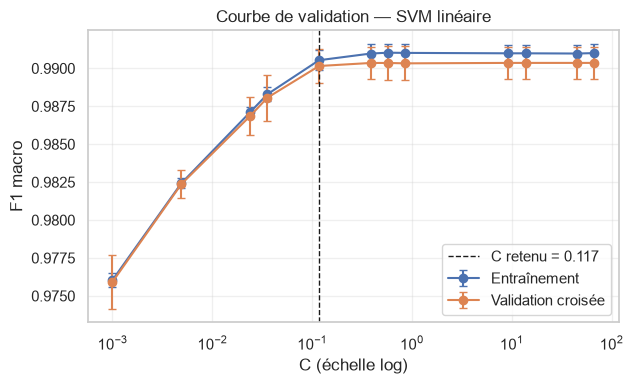

In [5]:
search = RandomizedSearchCV(make_svm("linear", best_strategy), {"model__C": np.logspace(-3, 2, 30)}, n_iter=12, cv=cv, scoring="f1_macro",
                            random_state=RS, n_jobs=3, refit=False, return_train_score=True)
search.fit(Xs, ys); res = pd.DataFrame(search.cv_results_).sort_values("param_model__C")
res["C"] = res["param_model__C"].astype(float)
display(res[["C", "mean_train_score", "mean_test_score", "std_test_score"]].round(4))
# parcimonie : plateau de C -> le plus petit C (marge la plus large, modèle le plus régularisé) à moins d'un écart-type du meilleur
ib = res["mean_test_score"].idxmax(); floor = res.loc[ib, "mean_test_score"] - res.loc[ib, "std_test_score"]
best_C = float(res.loc[res["mean_test_score"] >= floor, "C"].min())
print(f"C au meilleur score brut : {res.loc[ib, 'C']:.3g} ; C retenu (parcimonie, le plus petit à 1 écart-type) : {best_C:.3g}")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(res.C, res.mean_train_score, yerr=res.std_train_score, fmt="o-", capsize=3, label="Entraînement")
ax.errorbar(res.C, res.mean_test_score, yerr=res.std_test_score, fmt="o-", capsize=3, label="Validation croisée")
ax.axvline(best_C, color="k", ls="--", lw=1, label=f"C retenu = {best_C:.3g}"); ax.set_xscale("log")
ax.set(xlabel="C (échelle log)", ylabel="F1 macro", title="Courbe de validation — SVM linéaire"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); U.savefig(fig, "03_validation_curve_C"); plt.show()

## 4. SVM à noyau RBF
Le noyau RBF capture des frontières **non linéaires**. Le SVM exact coûte ≈ O(n²) à O(n³) en temps et O(n²) en mémoire : l'apprentissage sur 65 000 lignes serait prohibitif (et le comparer
à un modèle entraîné sur tout le train n'aurait pas de sens). On règle donc `C` et `gamma` par CV sur **10 000 lignes** stratifiées (par type) puis on entraîne sur un **sous-échantillon stratifié de 25 000 lignes** ;
`n_train_rows` est consigné dans les résultats pour que la comparaison finale soit honnête.
- `C` : pénalité des erreurs · `gamma` : portée d'un point (grand = frontière très locale)

Grille RBF : 49s


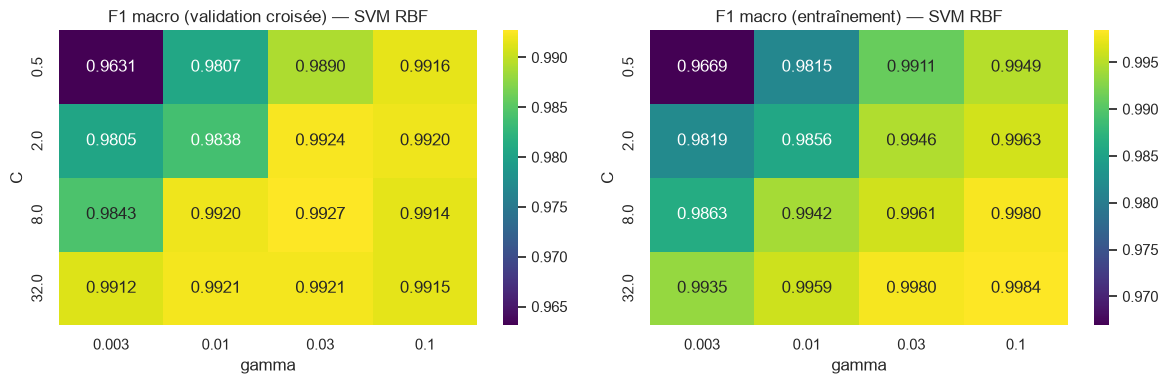

Meilleurs (C, gamma) : {'C': 8.0, 'gamma': 0.03}


In [6]:
tune_idx, _ = train_test_split(X_train.index, train_size=10000, stratify=y_tr["type"], random_state=RS)
fit_idx, _ = train_test_split(X_train.index, train_size=25000, stratify=y_tr["type"], random_state=RS)
grid = GridSearchCV(make_svm("rbf", best_strategy), {"model__C": [0.5, 2, 8, 32], "model__gamma": [0.003, 0.01, 0.03, 0.1]},
                    cv=cv, scoring="f1_macro", n_jobs=N_JOBS, return_train_score=True, refit=False)
t0 = time.time(); grid.fit(X_train.loc[tune_idx], ytr[tune_idx]); print(f"Grille RBF : {time.time()-t0:.0f}s")
g = pd.DataFrame(grid.cv_results_)
piv = g.pivot(index="param_model__C", columns="param_model__gamma", values="mean_test_score").astype(float)
piv_tr = g.pivot(index="param_model__C", columns="param_model__gamma", values="mean_train_score").astype(float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(piv, annot=True, fmt=".4f", cmap="viridis", ax=axes[0]); axes[0].set(title="F1 macro (validation croisée) — SVM RBF", xlabel="gamma", ylabel="C")
sns.heatmap(piv_tr, annot=True, fmt=".4f", cmap="viridis", ax=axes[1]); axes[1].set(title="F1 macro (entraînement) — SVM RBF", xlabel="gamma", ylabel="C")
plt.tight_layout(); U.savefig(fig, "03_rbf_grid"); plt.show()
best_rbf = {"C": float(grid.best_params_["model__C"]), "gamma": float(grid.best_params_["model__gamma"])}; print("Meilleurs (C, gamma) :", best_rbf)

## 5. Approximation du noyau RBF (Nyström) + SVM linéaire
`Nystroem` projette les données dans un espace de 300 dimensions où le produit scalaire approche le noyau RBF ; un SVM **linéaire** y est appris sur **tout le train** en quelques secondes.
C'est le compromis classique entre la puissance du RBF et le coût du SVM exact. On réutilise `(C, gamma)` du RBF exact (approximation).

In [7]:
variants, fit_times, n_rows = {}, {}, {}
specs = {"SVM linéaire": ("linear", dict(C=best_C), None),
         "SVM RBF (25k lignes)": ("rbf", best_rbf, fit_idx),
         "RBF Nyström + linéaire": ("nystroem", dict(gamma=best_rbf["gamma"], C=best_rbf["C"]), None)}
for name, (kind, params, idx) in specs.items():
    Xf, yf = (X_train, ytr) if idx is None else (X_train.loc[idx], ytr[X_train.index.get_indexer(idx)])
    t0 = time.time(); variants[name] = make_svm(kind, best_strategy, **params).fit(Xf, yf)
    fit_times[name] = time.time() - t0; n_rows[name] = len(Xf)
    print(f"{name:26s} entraîné en {fit_times[name]:6.1f}s sur {n_rows[name]} lignes")

SVM linéaire               entraîné en    3.3s sur 65007 lignes


SVM RBF (25k lignes)       entraîné en    2.6s sur 25000 lignes


RBF Nyström + linéaire     entraîné en   12.7s sur 65007 lignes


## 6. Comparaison des variantes (validation) et choix du modèle
Les trois variantes sont comparées sur la **même validation** (marge > 0), avec leur temps d'entraînement, leur nombre de lignes d'apprentissage et leur temps de prédiction. Le SVM retenu est celui au meilleur **F1 macro de validation**.

,accuracy,precision,recall,specificity,f1,f1_macro,f1_macro_train,roc_auc,pr_auc,mcc,n_train_rows,fit_s,predict_ms_per_1k
SVM linéaire,0.9926,0.9934,0.9970,0.9776,0.9952,0.9895,0.9910,0.9983,0.9994,0.9790,65007.0000,3.2988,5.6173
SVM RBF (25k lignes),0.9964,0.9969,0.9984,0.9896,0.9977,0.9949,0.9948,0.9991,0.9996,0.9898,25000.0000,2.5866,71.9681
RBF Nyström + linéaire,0.9946,0.9966,0.9964,0.9886,0.9965,0.9924,0.9929,0.9992,0.9997,0.9848,65007.0000,12.6982,15.6816


=> Modèle SVM retenu (meilleur F1 macro en validation) : SVM RBF (25k lignes)


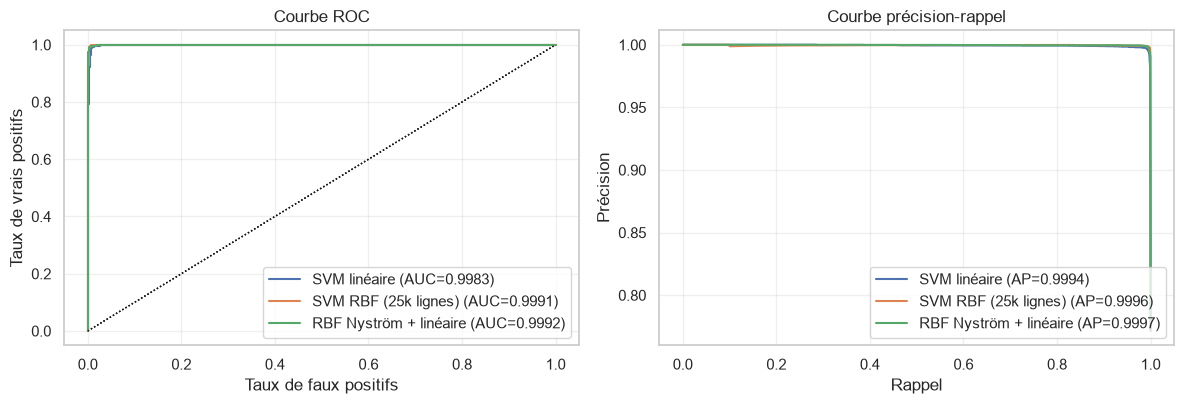

In [8]:
sv, pt = {}, {}
for n, m in variants.items():
    sv[n] = score_fn(m, X_valid); pt[n] = U.measure_predict_time(lambda X, m=m: score_fn(m, X), X_valid, repeats=1)
def gap_row(n):
    s_t = score_fn(variants[n], X_train.loc[tr_eval]); y_t = ytr[X_train.index.get_indexer(tr_eval)]
    return U.binary_metrics(y_t, (s_t > 0).astype(int))["f1_macro"]
cmp_ = pd.DataFrame({n: {**U.binary_metrics(yva, (s > 0).astype(int), scores=s), "f1_macro_train": gap_row(n), "n_train_rows": n_rows[n],
                        "fit_s": fit_times[n], "predict_ms_per_1k": pt[n]} for n, s in sv.items()}).T
display(cmp_[["accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "f1_macro_train", "roc_auc", "pr_auc", "mcc", "n_train_rows", "fit_s", "predict_ms_per_1k"]].round(4))
retained = cmp_["f1_macro"].astype(float).idxmax(); print(f"=> Modèle SVM retenu (meilleur F1 macro en validation) : {retained}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for n, s in sv.items(): U.plot_roc_pr(yva, s, n, axes=axes)
plt.tight_layout(); U.savefig(fig, "03_variants_roc_pr"); plt.show()

F1 macro train (échantillon 20k) = 0.9948 | validation = 0.9949 | écart = -0.0001


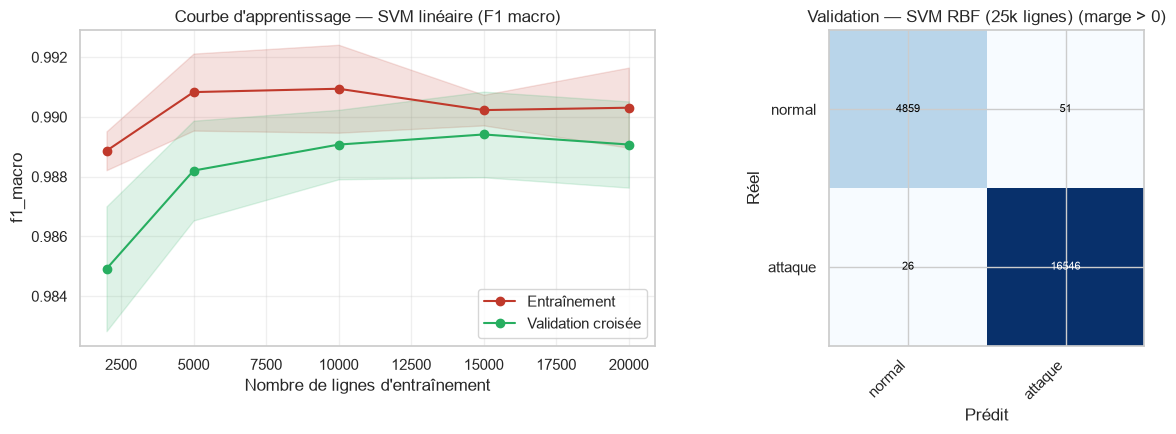

In [9]:
final = variants[retained]; s_va = sv[retained]
m_va = U.binary_metrics(yva, (s_va > 0).astype(int), scores=s_va)
print(f"F1 macro train (échantillon 20k) = {cmp_.loc[retained, 'f1_macro_train']:.4f} | validation = {m_va['f1_macro']:.4f} | écart = {cmp_.loc[retained, 'f1_macro_train'] - m_va['f1_macro']:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
U.plot_learning_curve(make_svm("linear", best_strategy, C=best_C), Xs.iloc[:30000], ys[:30000], cv=cv, scoring="f1_macro",
                      title="Courbe d'apprentissage — SVM linéaire (F1 macro)", ax=axes[0], train_sizes=[.1, .25, .5, .75, 1.0], n_jobs=3)
U.plot_confusion(confusion_matrix(yva, (s_va > 0).astype(int)), ["normal", "attaque"], f"Validation — {retained} (marge > 0)", ax=axes[1])
plt.tight_layout(); U.savefig(fig, "03_learning_curve"); plt.show()

## 7. Seuil et calibration (validation uniquement)

### 7.a Seuil sur la marge
Le seuil naturel est 0. `U.best_threshold` cherche, **sur la validation**, celui qui maximise le **F1 macro**.

Seuil optimal sur la marge = 0.4142 (F1 macro validation = 0.9947) ; à 0 : 0.9949


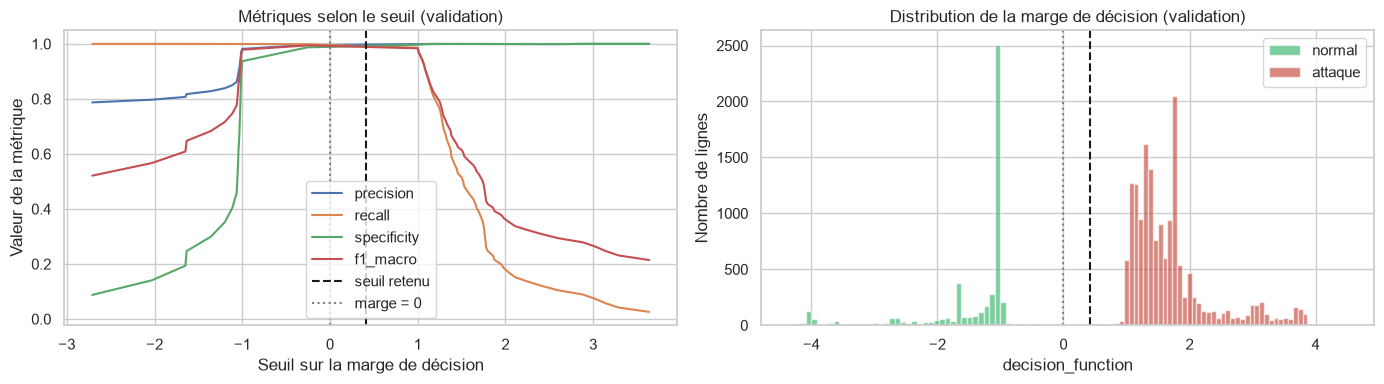

In [10]:
thr, f1m_valid_thr = U.best_threshold(yva, s_va, metric="f1_macro")
print(f"Seuil optimal sur la marge = {thr:.4f} (F1 macro validation = {f1m_valid_thr:.4f}) ; à 0 : {m_va['f1_macro']:.4f}")
grid_t = np.unique(np.quantile(s_va, np.linspace(.02, .98, 80)))
keep = ("precision", "recall", "specificity", "f1_macro")
cur = pd.DataFrame([{"seuil": t, **{k: v for k, v in U.binary_metrics(yva, (s_va >= t).astype(int)).items() if k in keep}} for t in grid_t]).set_index("seuil")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cur.plot(ax=axes[0]); axes[0].axvline(thr, color="k", ls="--", label="seuil retenu"); axes[0].axvline(0, color="grey", ls=":", label="marge = 0")
axes[0].set(title="Métriques selon le seuil (validation)", xlabel="Seuil sur la marge de décision", ylabel="Valeur de la métrique"); axes[0].legend()
for lab, c in [(0, "#27ae60"), (1, "#c0392b")]: axes[1].hist(s_va[yva == lab], bins=80, alpha=.6, color=c, label=["normal", "attaque"][lab])
axes[1].axvline(0, color="grey", ls=":"); axes[1].axvline(thr, color="k", ls="--")
axes[1].set(title="Distribution de la marge de décision (validation)", xlabel="decision_function", ylabel="Nombre de lignes"); axes[1].legend()
plt.tight_layout(); U.savefig(fig, "03_threshold_margin"); plt.show()

### 7.b Calibration des probabilités
`U.select_calibrator` compare Platt (régression logistique sur la marge) et isotonique : ajustement sur une moitié de la validation, Brier sur l'autre moitié, gagnant réajusté sur toute la validation.
**Le test n'intervient pas dans ce choix.** Le diagramme de fiabilité sur le test sert uniquement à vérifier.

In [11]:
cal_name, cal_fn, brier_valid = U.select_calibrator(s_va, yva, random_state=RS, is_probability=False)
print("Brier (moitié B de la validation) :"); display(brier_valid.to_frame().T.round(5)); print("Calibrateur retenu :", cal_name)

Brier (moitié B de la validation) :


,platt,isotonic
brier,0.0024,0.0026


Calibrateur retenu : platt


## 8. Évaluation finale sur le test (une seule lecture)
Seuil par défaut (marge > 0) et seuil réglé sur la validation. Le notebook 07 utilise le **seuil réglé** (clé `test`).

,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,mcc,fpr,fnr,roc_auc,pr_auc,tn,fp,fn,tp
Marge > 0 (défaut),0.9965,0.9943,0.9972,0.9983,0.9903,0.9977,0.9950,0.9965,0.9900,0.0097,0.0017,0.9989,0.9994,4819.0000,47.0000,28.0000,16544.0000
Seuil réglé (valid),0.9965,0.9955,0.9981,0.9973,0.9936,0.9977,0.9950,0.9965,0.9899,0.0064,0.0027,0.9989,0.9994,4835.0000,31.0000,45.0000,16527.0000


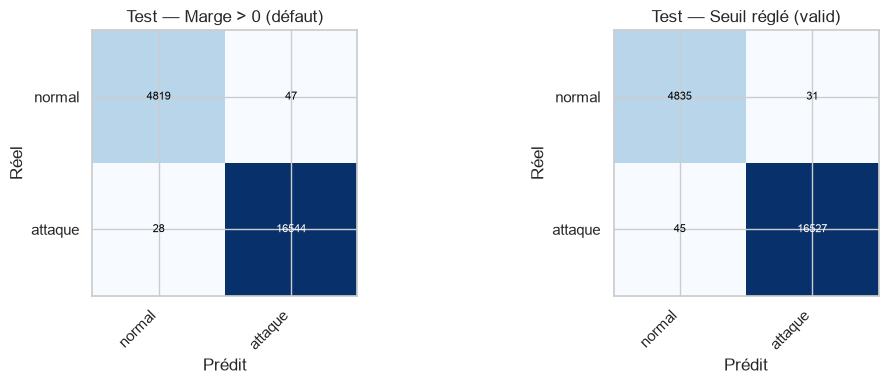

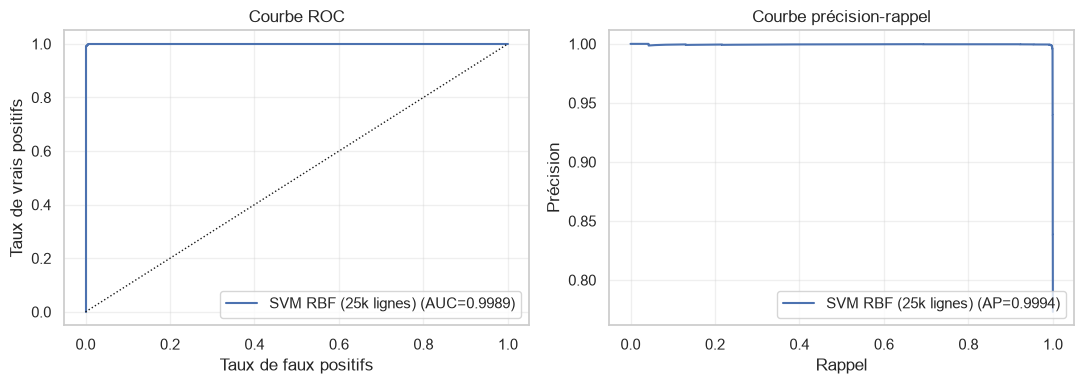

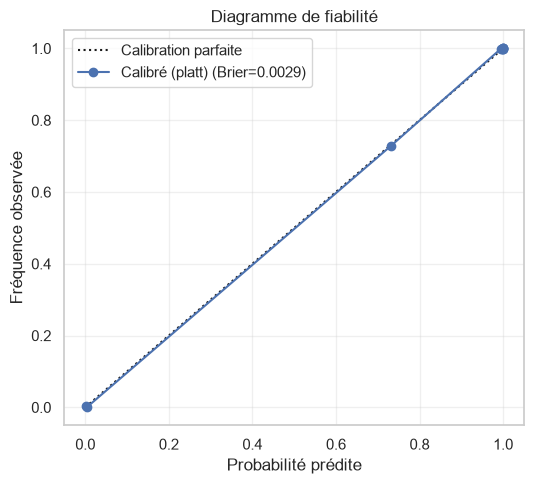

Brier test (information, non utilisé pour choisir) : {'platt': 0.00287}
Temps de prédiction : 72.0 ms / 1000 lignes (mesuré sur la validation)


In [12]:
s_te = score_fn(final, X_test); p_te_cal = cal_fn(s_te)
pred = {"Marge > 0 (défaut)": (s_te > 0).astype(int), "Seuil réglé (valid)": (s_te >= thr).astype(int)}
test_tbl = pd.DataFrame({k: U.binary_metrics(yte, v, scores=s_te, proba=p_te_cal) for k, v in pred.items()}).T
display(test_tbl[["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "f1_weighted", "mcc", "fpr", "fnr", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (k, v) in zip(axes, pred.items()): U.plot_confusion(confusion_matrix(yte, v), ["normal", "attaque"], f"Test — {k}", ax=ax)
plt.tight_layout(); U.savefig(fig, "03_test_confusions"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); U.plot_roc_pr(yte, s_te, retained, axes=axes); plt.tight_layout(); U.savefig(fig, "03_test_roc_pr"); plt.show()
fig, ax = plt.subplots(figsize=(5.5, 5)); U.plot_calibration(yte, {f"Calibré ({cal_name})": p_te_cal}, ax=ax)
plt.tight_layout(); U.savefig(fig, "03_calibration"); plt.show()
brier_test = {cal_name: float(brier_score_loss(yte, p_te_cal))}
print("Brier test (information, non utilisé pour choisir) :", {k: round(v, 5) for k, v in brier_test.items()})
t_pred = pt[retained]; print(f"Temps de prédiction : {t_pred:.1f} ms / 1000 lignes (mesuré sur la validation)")

## 9. Interprétation et analyse des erreurs
Coefficients du SVM **linéaire** (variables standardisées : comparables entre elles) et importance par permutation du modèle **retenu** (échantillon de 3 000 lignes de validation).

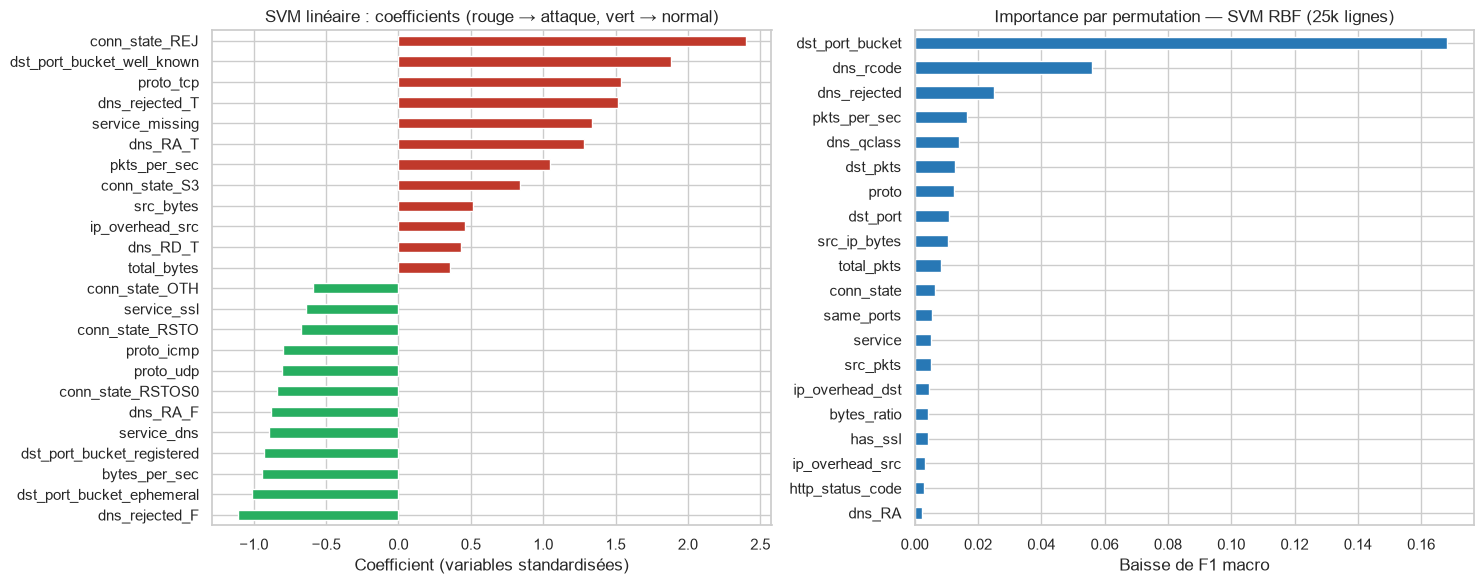

Top 5 coefficients absolus : ['conn_state_REJ', 'dst_port_bucket_well_known', 'proto_tcp', 'dns_rejected_T', 'service_missing']
Top 5 permutation : ['dst_port_bucket', 'dns_rcode', 'dns_rejected', 'pkts_per_sec', 'dns_qclass']


In [13]:
lin = variants["SVM linéaire"]; names = U.feature_names(lin.named_steps["pre"]); coef = pd.Series(lin.named_steps["model"].coef_.ravel(), index=names).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pd.concat([coef.head(12), coef.tail(12)]).plot(kind="barh", ax=axes[0], color=["#27ae60"] * 12 + ["#c0392b"] * 12)
axes[0].set(title="SVM linéaire : coefficients (rouge → attaque, vert → normal)", xlabel="Coefficient (variables standardisées)")
sidx = X_valid.sample(3000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[X_valid.index.get_indexer(sidx)], scoring="f1_macro", n_repeats=2, random_state=RS, n_jobs=N_JOBS)
pi_s = pd.Series(pi.importances_mean, index=X_valid.columns).sort_values(ascending=False)
pi_s.head(20).iloc[::-1].plot(kind="barh", ax=axes[1], color="#2878b5"); axes[1].set(title=f"Importance par permutation — {retained}", xlabel="Baisse de F1 macro")
plt.tight_layout(); U.savefig(fig, "03_importances"); plt.show()
print("Top 5 coefficients absolus :", list(coef.abs().sort_values(ascending=False).head(5).index)); print("Top 5 permutation :", list(pi_s.head(5).index))

,n,erreurs,taux_erreur
type,,,
normal,4866,31,0.0064
ransomware,247,1,0.0040
scanning,1187,1,0.0008
backdoor,485,0,0.0000
dos,2882,8,0.0028
mitm,198,13,0.0657
xss,1745,3,0.0017
ddos,2657,14,0.0053
injection,3956,3,0.0008


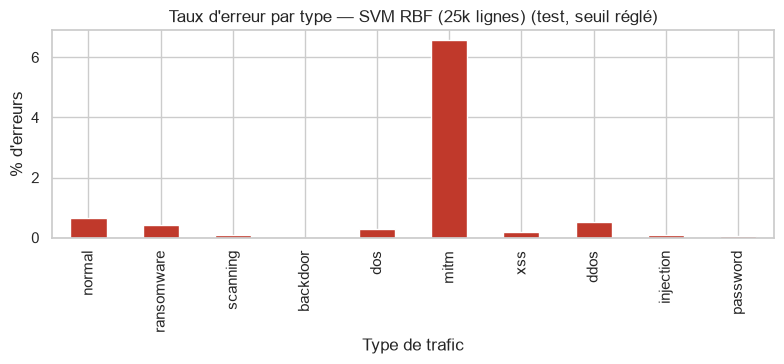

,TP,TN,FP,FN
dns_rcode,0.0000,0.0000,0.0000,0.0000
pkts_per_sec,328.2460,488.3670,28.0470,117.4050
dns_qclass,0.0000,0.0000,0.0000,0.0000
dst_pkts,2.0000,0.0000,7.0000,1.0000
dst_port,80.0000,1395.0000,443.0000,53.0000
src_ip_bytes,228.0000,560.0000,852.0000,108.0000
total_pkts,6.0000,6.0000,14.0000,4.0000
same_ports,0.0000,0.0000,0.0000,0.0000


In [14]:
err = pd.DataFrame({"type": y_te["type"].to_numpy(), "label": yte, "pred": pred["Seuil réglé (valid)"]}); err["erreur"] = err.label != err.pred
by_type = err.groupby("type").agg(n=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean")).reindex(TYPE_ORDER)
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.8)); by_type["taux_erreur"].mul(100).plot(kind="bar", ax=ax, color="#c0392b")
ax.set(xlabel="Type de trafic", ylabel="% d'erreurs", title=f"Taux d'erreur par type — {retained} (test, seuil réglé)")
plt.tight_layout(); U.savefig(fig, "03_error_by_type"); plt.show()
grp = np.select([(err.label == 1) & (err.pred == 1), (err.label == 0) & (err.pred == 0), (err.label == 0) & (err.pred == 1)], ["TP", "TN", "FP"], "FN")
top_num = [c for c in pi_s.index if c in NUM][:8]
med = X_test[top_num].groupby(grp).median().T.round(3)
display(med[[c for c in ["TP", "TN", "FP", "FN"] if c in med.columns]])

## 10. Sauvegarde

In [15]:
joblib.dump(final, U.MODEL_DIR / "svm_anomaly.joblib", compress=3)
params_out = {"variante": retained, "linear_C": best_C, "rbf_C": best_rbf["C"], "rbf_gamma": best_rbf["gamma"], "rbf_train_rows": n_rows["SVM RBF (25k lignes)"], "nystroem_n_components": 300}
U.save_result("03_svm_anomaly", {
    "task": "Détection d'anomalies (label binaire)", "model": f"SVM ({retained})", "strategy": best_strategy, "params": params_out,
    "n_train_rows": n_rows[retained], "fit_time_s": fit_times[retained], "predict_time_ms_per_1k": t_pred,
    "threshold": thr, "threshold_metric": "f1_macro (validation)", "calibrator": cal_name, "calibration_brier_valid_halfB": brier_valid.to_dict(),
    "cv": {"protocole": "StratifiedKFold(3), 50k lignes du train (SVM linéaire)", "selection": "parcimonie (1 écart-type)", "table": bal.to_dict("index")},
    "baseline_valid": base_valid, "variants_valid": cmp_.to_dict("index"), "valid_default_threshold": m_va,
    "valid": U.binary_metrics(yva, (s_va >= thr).astype(int), scores=s_va, proba=cal_fn(s_va)),
    "test": test_tbl.loc["Seuil réglé (valid)"].to_dict(), "test_default_threshold": test_tbl.loc["Marge > 0 (défaut)"].to_dict(),
    "brier_test": brier_test, "error_by_type": by_type["taux_erreur"].to_dict(),
    "limitations": [
        "Le SVM RBF exact est limité à 25 000 lignes d'apprentissage (coût O(n²)) ; le SVM linéaire et Nyström voient tout le train : les nombres de lignes diffèrent (voir n_train_rows).",
        "Hyper-paramètres réglés sur 10 000 à 50 000 lignes seulement, seuil et calibrateur sur la validation, jamais sur le test.",
        "Données d'un banc d'essai scripté (TON_IoT) : performance non transférable telle quelle à un autre réseau.",
        "Modèle supervisé : ne détecte pas des attaques absentes de l'entraînement ; marge non probabiliste (calibration Platt / isotonique a posteriori).",
    ]})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


In [16]:
display(Markdown(f"""### Chiffres clés (générés par le code)
- Stratégie : **{U.STRATEGY_LABELS[best_strategy]}** (argmax brut : {U.STRATEGY_LABELS[argmax_strategy]}) ; C linéaire {best_C:.3g} ; RBF {best_rbf}
- Variante retenue : **{retained}** ({n_rows[retained]} lignes d'apprentissage, {fit_times[retained]:.0f}s)
- F1 macro : train {cmp_.loc[retained, 'f1_macro_train']:.4f} / validation (marge > 0) {m_va['f1_macro']:.4f} / test (seuil réglé) {test_tbl.loc['Seuil réglé (valid)','f1_macro']:.4f}
- Seuil réglé {thr:.3f} ; calibrateur {cal_name} ; prédiction {t_pred:.0f} ms / 1000 lignes
"""))

### Chiffres clés (générés par le code)
- Stratégie : **Aucun** (argmax brut : Aucun) ; C linéaire 0.117 ; RBF {'C': 8.0, 'gamma': 0.03}
- Variante retenue : **SVM RBF (25k lignes)** (25000 lignes d'apprentissage, 3s)
- F1 macro : train 0.9948 / validation (marge > 0) 0.9949 / test (seuil réglé) 0.9950
- Seuil réglé 0.414 ; calibrateur platt ; prédiction 72 ms / 1000 lignes


## Conclusion (SVM — détection d'anomalies)

Chiffres tirés des sorties ci-dessus (cellule « Chiffres clés » et §3 à §9).
- **Équilibrage** : pour le SVM linéaire, aucune stratégie ne bat significativement les autres en F1 macro (≈ 0,990 ± 0,001) ; la parcimonie retient **aucun rééchantillonnage**. Les poids de classe / ROS / SMOTE / SMOTENC déplacent le point de fonctionnement (spécificité 0,991 contre 0,984, rappel 0,993 contre 0,996) sans gain net de F1 macro.
- **Réglage de C** : le score plafonne dès C ≈ 0,1 ; le `C` retenu est le plus petit du plateau (0,117), un `argmax` donnerait un `C` arbitraire parmi des valeurs équivalentes.
- **Variantes** (validation, F1 macro) : linéaire 0,9895 < Nyström + linéaire 0,9924 < **RBF exact 0,9949**, retenu. Le noyau RBF apporte donc un gain réel (frontière non linéaire), obtenu avec **25 000 lignes** seulement (le linéaire et Nyström voient 65 007 lignes) ; la comparaison avec le Random Forest (0,9968 sur tout le train) doit tenir compte de `n_train_rows`. Le RBF est aussi le plus lent à la prédiction (≈ 72 ms / 1000 lignes contre ≈ 6 ms pour le linéaire).
- **Écart train / validation** : 0,9948 contre 0,9949 pour le RBF retenu, aucun surapprentissage (au contraire du RF) ; le modèle est limité par sa capacité plus que par la variance.
- **Seuil et calibration** : le seuil réglé (≈ 0,41) ne change pas le F1 macro de validation ni de test (0,9950) ; il améliore la spécificité (0,994 contre 0,990) au prix du rappel. Platt est choisi sur la moitié B de la validation (Brier plus bas que l'isotonique).
- **Erreurs** : comme le RF, `mitm` est la classe la plus difficile (≈ 6,6 % d'erreur) ; le SVM fait plus d'erreurs que le RF sur `normal`, `ddos` et `dos`.
- **Mise en garde** : scores toujours très élevés (jeu séparable, banc d'essai scripté) ; l'importance par permutation est portée par des variables de service (catégorie de port, champs DNS). Non transférable tel quel à un autre réseau.